In [3]:
import spatialdata as sd
import decoupler as dc
from spatialdata_io import xenium

import numpy as np
import pandas as pd
import scipy.sparse as sp


import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import anndata as ad

import scanpy as sc

import squidpy as sq

sc.set_figure_params(figsize=(12,12))
mpl.rcParams['figure.dpi'] = 300



In [4]:
Sample_895=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_895.h5ad")
Sample_894=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_894.h5ad")
Sample_898=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_898.h5ad")


Sample_896=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_896.h5ad")
Sample_897=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_897.h5ad")
Sample_18=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_18.h5ad")


Sample_886=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_886.h5ad")
Sample_890=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_890.h5ad")
Sample_891=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_891.h5ad")


Sample_4=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_4.h5ad")
Sample_5=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_5.h5ad")
Sample_3=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_3.h5ad")


In [56]:
adatas = Sample_895.concatenate(Sample_894,Sample_898,Sample_896,Sample_897,Sample_18,Sample_886,Sample_890,Sample_891,Sample_4,Sample_5,Sample_3)

/tmp/ipykernel_2288920/3313751384.py:1: FutureWarning: Use anndata.concat instead of AnnData.concatenate, AnnData.concatenate is deprecated and will be removed in the future. See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  adatas = Sample_895.concatenate(Sample_894,Sample_898,Sample_896,Sample_897,Sample_18,Sample_886,Sample_890,Sample_891,Sample_4,Sample_5,Sample_3)


In [57]:
adatas.layers["counts"] = adatas.X.copy()
adatas.obs_names_make_unique()

In [58]:
sc.pp.normalize_total(adatas)
sc.pp.log1p(adatas)

In [81]:
sc.tl.rank_genes_groups(adatas, 'Class', method='wilcoxon',pts=True)

In [82]:
rank_genes_df = sc.get.rank_genes_groups_df(adatas, group=None)

In [ ]:
rank_genes_df

In [104]:
rank_genes_df.to_excel("/exports/humgen/qmao/Xenium_celltype_rank_genes.xlsx", index=False, engine="openpyxl")

In [83]:
filtered_genes = rank_genes_df[(rank_genes_df['pvals_adj'] <0.05)]

In [84]:
filtered_genes

,group,names,scores,logfoldchanges,pvals,pvals_adj,pct_nz_group,pct_nz_reference
0,IT-ET Glut,Slc17a7,457.811005,2.684894,0.0,0.0,0.993832,0.588480
1,IT-ET Glut,Nrn1,429.990173,2.279803,0.0,0.0,0.991848,0.679693
2,IT-ET Glut,Arpp21,403.892670,1.971676,0.0,0.0,0.964120,0.676799
3,IT-ET Glut,Epha4,400.156830,2.107909,0.0,0.0,0.962999,0.661387
4,IT-ET Glut,2010300C02Rik,389.192322,2.180411,0.0,0.0,0.954107,0.546396
...,...,...,...,...,...,...,...,...
4747,Immune,Rims3,-165.542816,-2.139771,0.0,0.0,0.369749,0.733034
4748,Immune,Map2,-166.851532,-0.988887,0.0,0.0,0.953856,0.987398
4749,Immune,Nrn1,-174.061676,-2.360775,0.0,0.0,0.398268,0.742472
4750,Immune,Arpp21,-181.063019,-2.381316,0.0,0.0,0.321060,0.739064


In [85]:
filtered_genes = rank_genes_df[(rank_genes_df['logfoldchanges'] > 1)]

In [86]:
filtered_genes = rank_genes_df[(rank_genes_df['logfoldchanges'] > 1) &
    (rank_genes_df['pct_nz_group'] > 0.7) &
    (rank_genes_df['pct_nz_reference'] < 0.5)]


In [87]:
top_genes_per_cluster = (
    filtered_genes.groupby('group')  # 'group' column represents clusters
    .apply(lambda x: x.nlargest(3, 'logfoldchanges'))  # Select top 5 genes by logFC
    .reset_index(drop=True)
)

# Extract unique gene names
selected_genes = top_genes_per_cluster['names'].unique()

/tmp/ipykernel_2288920/1694200658.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.nlargest(3, 'logfoldchanges'))  # Select top 5 genes by logFC


In [88]:
Class_order = [
    'IT-ET Glut', 'NP-CT-L6b Glut', 'DG-IMN Glut', 'CTX-CGE GABA', 'CTX-MGE GABA', 
    'CNU-LGE GABA', 'CNU-HYa GABA', 'CNU-HYa Glut', 'HY GABA', 'HY Glut', 
    'MH-LH Glut', 'TH Glut', 'Astro-Epen', 'OPC-Oligo', 'Vascular', 'Immune'
]

# Convert the `group` column to a categorical type with the desired order
top_genes_per_cluster["group"] = pd.Categorical(
    top_genes_per_cluster["group"],
    categories=Class_order,
    ordered=True
)

# Sort the DataFrame by the `group` column
top_genes_per_cluster = top_genes_per_cluster.sort_values(by="group")

In [91]:
selected_genes=top_genes_per_cluster["names"]

{'mainplot_ax': <Axes: >,
 'size_legend_ax': <Axes: title={'center': 'Fraction of cells\nin group (%)'}>,
 'color_legend_ax': <Axes: title={'center': 'Mean expression\nin group'}>}

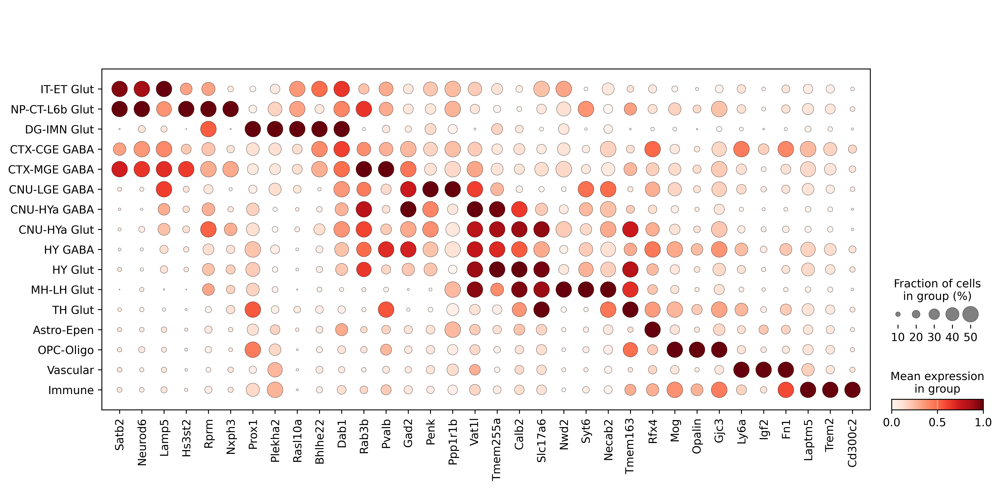

In [92]:
sc.pl.dotplot(adatas, var_names=selected_genes.unique(), groupby='Class', swap_axes=False,show=False, dot_max=0.5, standard_scale='var')

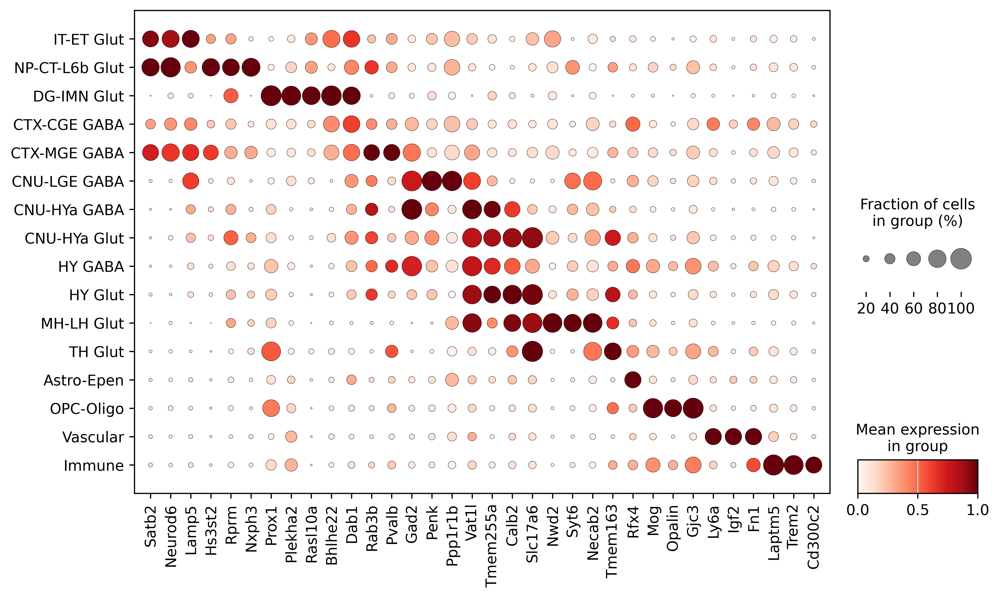

In [95]:
# Update rcParams for consistent formatting
plt.rcParams.update({
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'font.size': 12,
    'axes.titlesize': 12,
    'axes.labelsize': 12,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 12
})

mpl.rcParams['font.family'] = 'DejaVu Sans'  # or 'Arial'
mpl.rcParams['svg.fonttype'] = 'none'

width_per_gene = 0.3  # inches per gene (adjust to taste)
figsize = (len(selected_genes.unique()) * width_per_gene, 6)


sc.pl.dotplot(adatas, var_names=selected_genes.unique(),figsize=figsize,groupby='Class', swap_axes=False,show=False,categories_order=Class_order, dot_max=1.0, dot_min=0.0, smallest_dot=0.1, standard_scale='var')


plt.savefig(f"/exports/humgen/qmao/Dotplot_marker_class.svg",format="svg",dpi=300, bbox_inches='tight')

plt.show()

In [22]:
sc.tl.rank_genes_groups(adatas, 'Region', method='wilcoxon',pts=True)

/exports/archive/hg-exon-skip/Qirong/conda/envs/spatialdata/lib/python3.10/site-packages/scanpy/tools/_rank_genes_groups.py:429: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, "names"] = self.var_names[global_indices]
/exports/archive/hg-exon-skip/Qirong/conda/envs/spatialdata/lib/python3.10/site-packages/scanpy/tools/_rank_genes_groups.py:431: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, "scores"] = scores[global_indices]
/exports/archive/hg-exon-skip/Qirong/conda/envs/spatialdata/l

In [91]:
sc.tl.rank_genes_groups(adatas, 'Region', method='wilcoxon',pts=True)

/exports/archive/hg-exon-skip/Qirong/conda/envs/spatialdata/lib/python3.10/site-packages/scanpy/tools/_rank_genes_groups.py:429: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, "names"] = self.var_names[global_indices]
/exports/archive/hg-exon-skip/Qirong/conda/envs/spatialdata/lib/python3.10/site-packages/scanpy/tools/_rank_genes_groups.py:431: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, "scores"] = scores[global_indices]
/exports/archive/hg-exon-skip/Qirong/conda/envs/spatialdata/l

In [23]:
rank_genes_df = sc.get.rank_genes_groups_df(adatas, group=None)

In [93]:
rank_genes_df.to_excel("/exports/humgen/qmao/Xenium_region_rank_genes.xlsx", index=False, engine="openpyxl")

In [24]:
filtered_genes = rank_genes_df[(rank_genes_df['logfoldchanges'] > 0.5) &
    (rank_genes_df['pct_nz_group'] > 0.6) &
    (rank_genes_df['pct_nz_reference'] < 0.5)]


In [25]:
top_genes_per_cluster = (
    filtered_genes.groupby('group')  # 'group' column represents clusters
    .apply(lambda x: x.nlargest(3, 'logfoldchanges'))  # Select top 5 genes by logFC
    .reset_index(drop=True)
)

# Extract unique gene names
selected_genes = top_genes_per_cluster['names'].unique()

/tmp/ipykernel_2288920/1694200658.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.nlargest(3, 'logfoldchanges'))  # Select top 5 genes by logFC


In [31]:
# Define the specific order of row names (regions)
region_order = [
    'Cortex L1', 'Cortex L2/3', 'Cortex L4', 'Cortex L5', 'Cortex L6a', 'Cortex L6b','Retrosplenial cortex', 'Olfactory areas',
    'CA1', 'CA2/3', 'Dendate gyrus', 'HPF field', 'Thalamus 1', 'Thalamus 2', 'Reticular nucleus', 'Lateral habenula', 'Medial habenula','Hypothalamus', 
    'Basolateral amygdalar nucleus', 
    'Central amygdalar nucleus', 'Medial amygdalar nucleus', 'Caudoputamen',  'Ventricular system','Fiber tracts','Unassigned']  # Example

# Convert the `group` column to a categorical type with the desired order
top_genes_per_cluster["group"] = pd.Categorical(
    top_genes_per_cluster["group"],
    categories=region_order,
    ordered=True
)

# Sort the DataFrame by the `group` column
top_genes_per_cluster = top_genes_per_cluster.sort_values(by="group")
selected_genes=top_genes_per_cluster["names"]

In [97]:
top_genes_per_cluster 

,group,names,scores,logfoldchanges,pvals,pvals_adj,pct_nz_group,pct_nz_reference
15,Cortex L1,Fn1,110.268631,1.976749,0.0,0.0,0.609188,0.286636
17,Cortex L1,Dab1,69.483223,0.847345,0.0,0.0,0.644397,0.476787
16,Cortex L1,Nr2f2,73.708656,0.890096,0.0,0.0,0.707071,0.483487
20,Cortex L2/3,Gsg1l,246.543442,2.709409,0.0,0.0,0.794899,0.239527
18,Cortex L2/3,Lamp5,332.513245,3.650977,0.0,0.0,0.966173,0.333733
...,...,...,...,...,...,...,...,...
38,Fiber tracts,Gjc3,342.792786,3.187845,0.0,0.0,0.917974,0.455868
37,Fiber tracts,Opalin,280.234924,3.664527,0.0,0.0,0.730930,0.184927
69,Unassigned,Aldh1a2,213.402283,6.421819,0.0,0.0,0.652681,0.032425
70,Unassigned,Fmod,194.740021,6.015233,0.0,0.0,0.601919,0.039931


In [98]:
selected_genes=top_genes_per_cluster["names"]

adatas.obs["Region"].cat.reorder_categories(region_order)

0-0             Cortex L5
1-0             Cortex L5
2-0             Cortex L5
3-0             Cortex L5
4-0           Cortex L2/3
                 ...     
265017-11    Hypothalamus
265018-11    Hypothalamus
265019-11    Hypothalamus
265020-11    Hypothalamus
265021-11    Hypothalamus
Name: Region, Length: 949583, dtype: category
Categories (25, object): ['Cortex L1', 'Cortex L2/3', 'Cortex L4', 'Cortex L5', ..., 'Caudoputamen', 'Ventricular system', 'Fiber tracts', 'Unassigned']

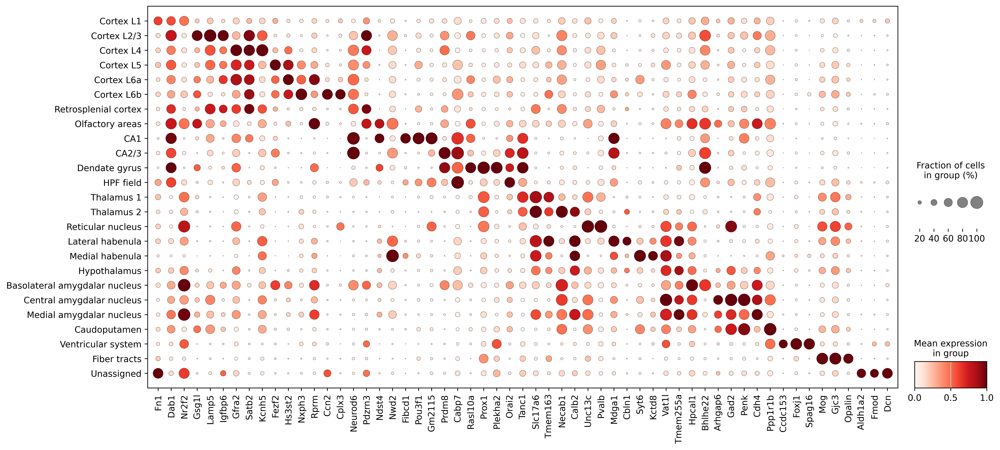

In [44]:
# Update rcParams for consistent formatting
plt.rcParams.update({
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'font.size': 12,
    'axes.titlesize': 12,
    'axes.labelsize': 12,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 12
})

mpl.rcParams['font.family'] = 'DejaVu Sans'  # or 'Arial'
mpl.rcParams['svg.fonttype'] = 'none'

width_per_gene = 0.3  # inches per gene (adjust to taste)
figsize = (len(selected_genes.unique()) * width_per_gene, 8)


sc.pl.dotplot(adatas, var_names=selected_genes.unique(),figsize=figsize,groupby='Region', swap_axes=False,show=False,categories_order=region_order, dot_max=1.0, dot_min=0.0, smallest_dot=0.1, standard_scale='var')


plt.savefig(f"/exports/humgen/qmao/Dotplot_marker_region.svg",format="svg",dpi=300, bbox_inches='tight')

plt.show()

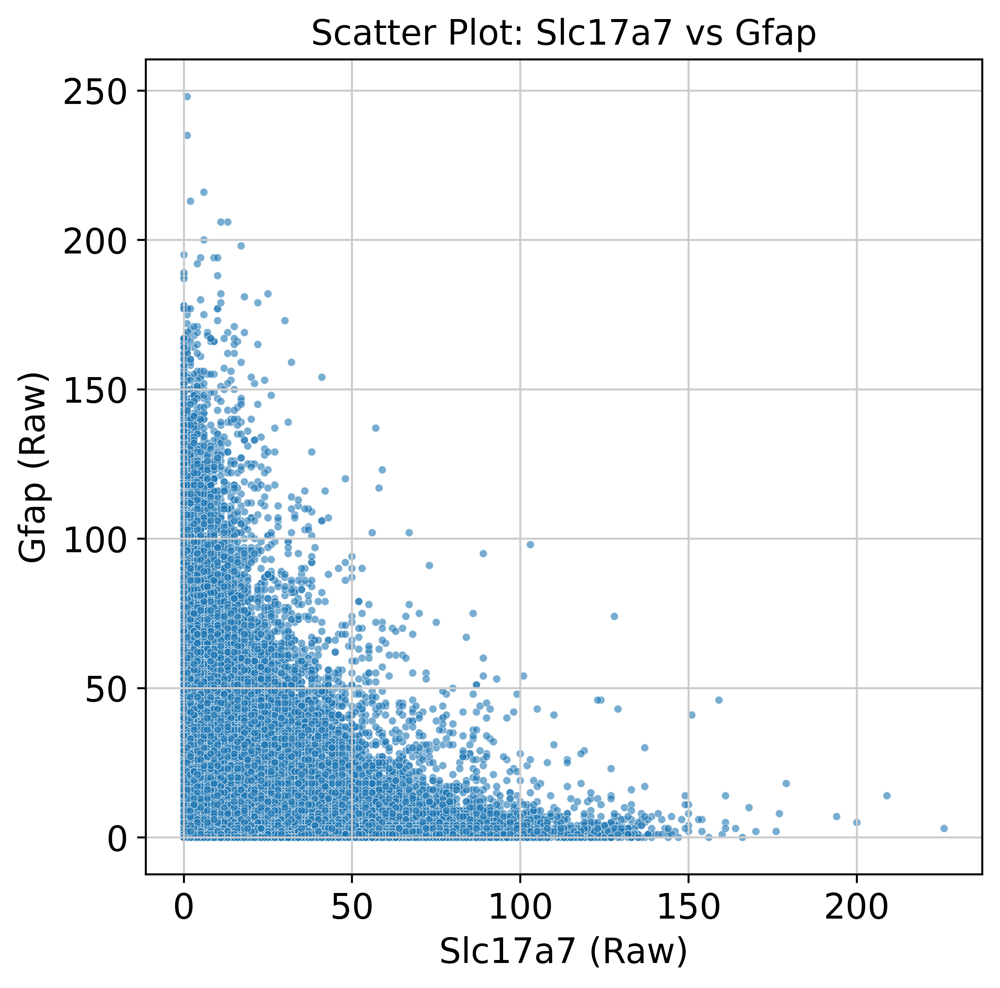

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

adata=adatas

# Replace with your gene names
gene1 = "Slc17a7"
gene2 = "Gfap"

# Extract log-normalized expression values
x = adata[:, gene1].X.toarray().flatten() if hasattr(adata[:, gene1].X, 'toarray') else adata[:, gene1].X.flatten()
y = adata[:, gene2].X.toarray().flatten() if hasattr(adata[:, gene2].X, 'toarray') else adata[:, gene2].X.flatten()

# Plot
plt.figure(figsize=(6, 6))
sns.scatterplot(x=x, y=y, s=10, alpha=0.6)
plt.xlabel(f'{gene1} (Raw)')
plt.ylabel(f'{gene2} (Raw)')
plt.title(f'Scatter Plot: {gene1} vs {gene2}')
plt.grid(True)
plt.show()

In [9]:
counts_df=counts_df.fillna(0)

In [10]:
counts_df

,895,894,898,896,897,18,886,890,891,4,5,3,706,707,709T
Region,,,,,,,,,,,,,,,
Cortex L1,1937.0,2129.0,2014.0,2342.0,1522.0,1355.0,7225.0,3020.0,2525.0,2152.0,2831.0,1423.0,1820.0,1402.0,1661.0
Cortex L2/3,4110.0,5848.0,2878.0,4664.0,3672.0,4361.0,5391.0,4396.0,4327.0,4701.0,3982.0,4527.0,2636.0,3708.0,4305.0
Cortex L4,4725.0,6223.0,4784.0,5563.0,3892.0,4008.0,3697.0,4683.0,4412.0,4264.0,3595.0,3903.0,5315.0,3502.0,4458.0
Cortex L5,4050.0,5436.0,4071.0,4099.0,3370.0,3970.0,4732.0,3955.0,3379.0,4032.0,3464.0,4074.0,4985.0,3196.0,3639.0
Cortex L6a,5192.0,6288.0,6271.0,5708.0,4425.0,4353.0,4222.0,5243.0,4427.0,5048.0,3956.0,4557.0,6233.0,4148.0,4805.0
Cortex L6b,1754.0,2299.0,1944.0,1799.0,1581.0,1583.0,4600.0,1941.0,1434.0,2075.0,1330.0,1535.0,2361.0,1335.0,1918.0
Retrosplenial cortex,1357.0,3250.0,795.0,3352.0,1657.0,2206.0,2035.0,2104.0,1677.0,1780.0,1700.0,1742.0,2108.0,504.0,2766.0
Olfactory areas,2599.0,3482.0,2244.0,2571.0,1956.0,2473.0,1443.0,1941.0,2396.0,2979.0,3269.0,2191.0,4073.0,2402.0,2335.0
CA1,956.0,1314.0,2236.0,947.0,1033.0,866.0,0.0,976.0,944.0,922.0,983.0,1181.0,1343.0,1060.0,756.0


In [11]:
# Step 1: Calculate the total number of cells for each sample (i.e., sum across rows for each column)
total_cells_per_sample = counts_df.sum(axis=0)

# Step 2: Calculate the percentage of cells in each region for each sample
percentage_df = counts_df.div(total_cells_per_sample, axis=1) * 100

In [12]:
total_cells_per_sample

895      73095.0
894      97103.0
898     108477.0
896      83507.0
897      60793.0
18       76939.0
886      73111.0
890      80494.0
891      76849.0
4        79224.0
5        69080.0
3        70911.0
706      99678.0
707      61802.0
709T     75124.0
dtype: float64

In [13]:
percentage_df

,895,894,898,896,897,18,886,890,891,4,5,3,706,707,709T
Region,,,,,,,,,,,,,,,
Cortex L1,2.649976,2.192517,1.856615,2.804555,2.503578,1.761135,9.882234,3.751832,3.285664,2.716349,4.098147,2.006741,1.825879,2.268535,2.211011
Cortex L2/3,5.622820,6.022471,2.653097,5.585161,6.040169,5.668127,7.373719,5.461277,5.630522,5.933808,5.764331,6.384059,2.644515,5.999806,5.730526
Cortex L4,6.464190,6.408659,4.410151,6.661717,6.402053,5.209322,5.056695,5.817825,5.741129,5.382207,5.204111,5.504083,5.332170,5.666483,5.934189
Cortex L5,5.540735,5.598179,3.752869,4.908571,5.543401,5.159932,6.472350,4.913410,4.396934,5.089367,5.014476,5.745230,5.001104,5.171354,4.843991
Cortex L6a,7.103085,6.475598,5.780949,6.835355,7.278799,5.657729,5.774781,6.513529,5.760648,6.371807,5.726694,6.426365,6.253135,6.711757,6.396092
Cortex L6b,2.399617,2.367589,1.792085,2.154310,2.600628,2.057474,6.291803,2.411360,1.865997,2.619156,1.925304,2.164685,2.368627,2.160124,2.553112
Retrosplenial cortex,1.856488,3.346961,0.732874,4.014035,2.725643,2.867206,2.783439,2.613859,2.182201,2.246794,2.460915,2.456601,2.114810,0.815508,3.681913
Olfactory areas,3.555647,3.585883,2.068641,3.078784,3.217476,3.214235,1.973711,2.411360,3.117802,3.760224,4.732195,3.089789,4.086157,3.886606,3.108194
CA1,1.307887,1.353202,2.061266,1.134037,1.699209,1.125567,0.000000,1.212513,1.228383,1.163789,1.422988,1.665468,1.347338,1.715155,1.006336


In [14]:
### Immune

In [81]:
# List of AnnData objects (e.g., adata1, adata2, ...)
adatas = [Sample_895, Sample_894, Sample_898,Sample_896,Sample_897,Sample_18,Sample_886,Sample_890,Sample_891,Sample_4,Sample_5,Sample_3,Sample_706,Sample_707,Sample_709T]  # Replace with your actual AnnData objects

# Initialize an empty list to store the counts per region for each sample in each AnnData object
region_counts = []

# Loop through each AnnData object to count occurrences of regions
for adata in adatas:
    # Count the occurrences of each region in the "Regions" column
    adata = adata[adata.obs["Class"].isin(["Immune"]), :]
    counts_per_region = adata.obs["Region"].value_counts()
    
    # Append the result (this will be a pandas Series for each adata)
    region_counts.append(counts_per_region)

# Convert the list of Series into a DataFrame
counts_df = pd.DataFrame(region_counts).transpose()

# Label columns (each corresponds to an AnnData object)
counts_df.columns = [f"adata{i+1}" for i in range(len(adatas))]
counts_df.columns = [adata.obs["Sample"].iloc[0] for adata in adatas]



In [82]:
# Define the specific order of row names (regions)
region_order = [
    'Cortex L1', 'Cortex L2/3', 'Cortex L4', 'Cortex L5', 'Cortex L6a', 'Cortex L6b','Retrosplenial cortex', 'Olfactory areas',
    'CA1', 'CA2/3', 'Dendate gyrus', 'HPF field', 'Thalamus 1', 'Thalamus 2', 'Reticular nucleus', 'Lateral habenula', 'Medial habenula','Hypothalamus', 
    'Basolateral amygdalar nucleus', 
    'Central amygdalar nucleus', 'Medial amygdalar nucleus', 'Caudoputamen',  'Ventricular system','Fiber tracts','Unassigned']  # Example

# Reorder rows based on the desired order (ensure all regions in `desired_region_order` exist in the counts_df index)
counts_df = counts_df.loc[region_order]

In [83]:
counts_df=counts_df.fillna(0)

In [84]:
counts_df

,895,894,898,896,897,18,886,890,891,4,5,3,706,707,709T
Region,,,,,,,,,,,,,,,
Cortex L1,27.0,89.0,72.0,35.0,31.0,16.0,1549.0,167.0,168.0,70.0,67.0,14.0,52.0,31.0,33.0
Cortex L2/3,1.0,7.0,3.0,3.0,4.0,1.0,29.0,3.0,3.0,6.0,1.0,3.0,1.0,3.0,0.0
Cortex L4,10.0,23.0,20.0,10.0,6.0,5.0,25.0,21.0,8.0,16.0,6.0,4.0,10.0,5.0,16.0
Cortex L5,15.0,27.0,50.0,10.0,14.0,12.0,136.0,23.0,23.0,22.0,9.0,7.0,18.0,5.0,16.0
Cortex L6a,19.0,25.0,77.0,23.0,18.0,15.0,248.0,58.0,43.0,34.0,18.0,10.0,38.0,13.0,28.0
Cortex L6b,31.0,45.0,54.0,22.0,33.0,12.0,700.0,72.0,85.0,49.0,41.0,18.0,48.0,18.0,32.0
Retrosplenial cortex,5.0,35.0,55.0,27.0,10.0,41.0,129.0,18.0,17.0,28.0,3.0,11.0,21.0,8.0,14.0
Olfactory areas,3.0,9.0,4.0,6.0,3.0,3.0,10.0,8.0,8.0,9.0,6.0,3.0,9.0,0.0,2.0
CA1,0.0,3.0,16.0,0.0,0.0,0.0,0.0,2.0,1.0,3.0,0.0,0.0,0.0,2.0,0.0


In [52]:
# Step 1: Calculate the total number of cells for each sample (i.e., sum across rows for each column)
total_cells_per_sample = counts_df.sum(axis=0)

# Step 2: Calculate the percentage of cells in each region for each sample
percentage_df = counts_df.div(total_cells_per_sample, axis=1) * 100

In [53]:
total_cells_per_sample

895       855.0
894      1385.0
898      2640.0
896      1036.0
897       777.0
18        860.0
886     15464.0
890      8388.0
891      7416.0
4        1272.0
5        1184.0
3         765.0
706      2020.0
707       974.0
709T     1189.0
dtype: float64

In [54]:
percentage_df

,895,894,898,896,897,18,886,890,891,4,5,3,706,707,709T
Region,,,,,,,,,,,,,,,
Cortex L1,3.157895,6.425993,2.727273,3.378378,3.989704,1.860465,10.016813,1.990939,2.265372,5.503145,5.658784,1.830065,2.574257,3.182752,2.775442
Cortex L2/3,0.116959,0.505415,0.113636,0.289575,0.514801,0.116279,0.187532,0.035765,0.040453,0.471698,0.084459,0.392157,0.049505,0.308008,0.000000
Cortex L4,1.169591,1.660650,0.757576,0.965251,0.772201,0.581395,0.161666,0.250358,0.107875,1.257862,0.506757,0.522876,0.495050,0.513347,1.345669
Cortex L5,1.754386,1.949458,1.893939,0.965251,1.801802,1.395349,0.879462,0.274201,0.310140,1.729560,0.760135,0.915033,0.891089,0.513347,1.345669
Cortex L6a,2.222222,1.805054,2.916667,2.220077,2.316602,1.744186,1.603725,0.691464,0.579827,2.672956,1.520270,1.307190,1.881188,1.334702,2.354920
Cortex L6b,3.625731,3.249097,2.045455,2.123552,4.247104,1.395349,4.526643,0.858369,1.146170,3.852201,3.462838,2.352941,2.376238,1.848049,2.691337
Retrosplenial cortex,0.584795,2.527076,2.083333,2.606178,1.287001,4.767442,0.834196,0.214592,0.229234,2.201258,0.253378,1.437908,1.039604,0.821355,1.177460
Olfactory areas,0.350877,0.649819,0.151515,0.579151,0.386100,0.348837,0.064666,0.095374,0.107875,0.707547,0.506757,0.392157,0.445545,0.000000,0.168209
CA1,0.000000,0.216606,0.606061,0.000000,0.000000,0.000000,0.000000,0.023844,0.013484,0.235849,0.000000,0.000000,0.000000,0.205339,0.000000


/exports/archive/hg-exon-skip/Qirong/conda/envs/spatialdata/lib/python3.10/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


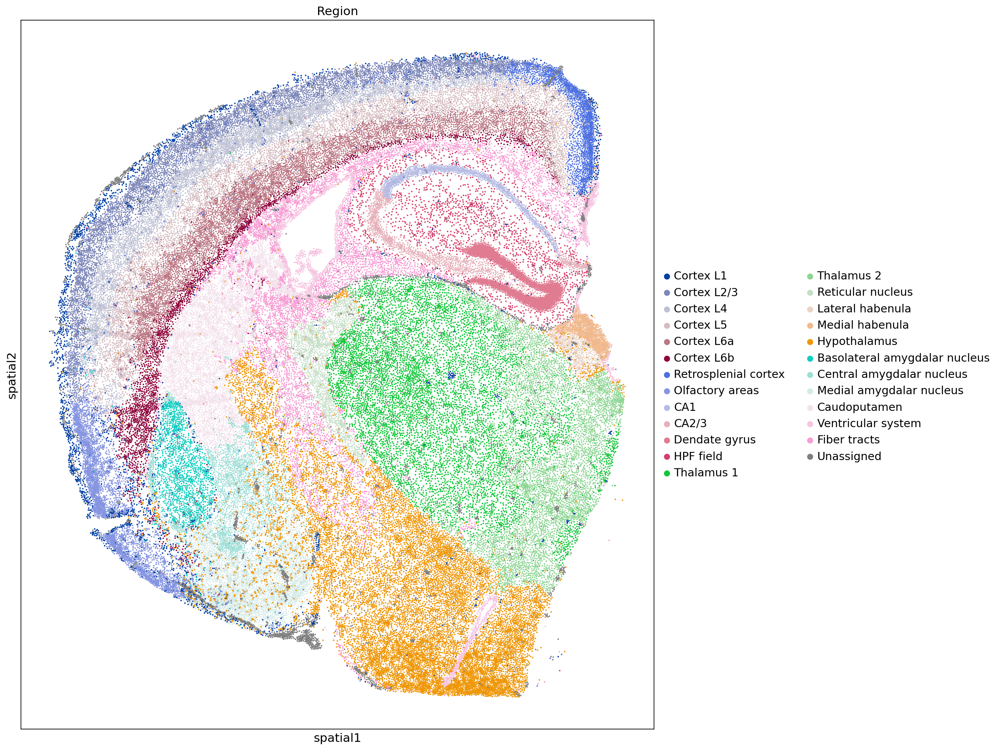

In [35]:
sq.pl.spatial_scatter(
    Sample_4,
    library_id="spatial",
    shape=None,
    color=[
        "Region",
    ],
    wspace=0.4,
)

/exports/archive/hg-exon-skip/Qirong/conda/envs/spatialdata/lib/python3.10/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


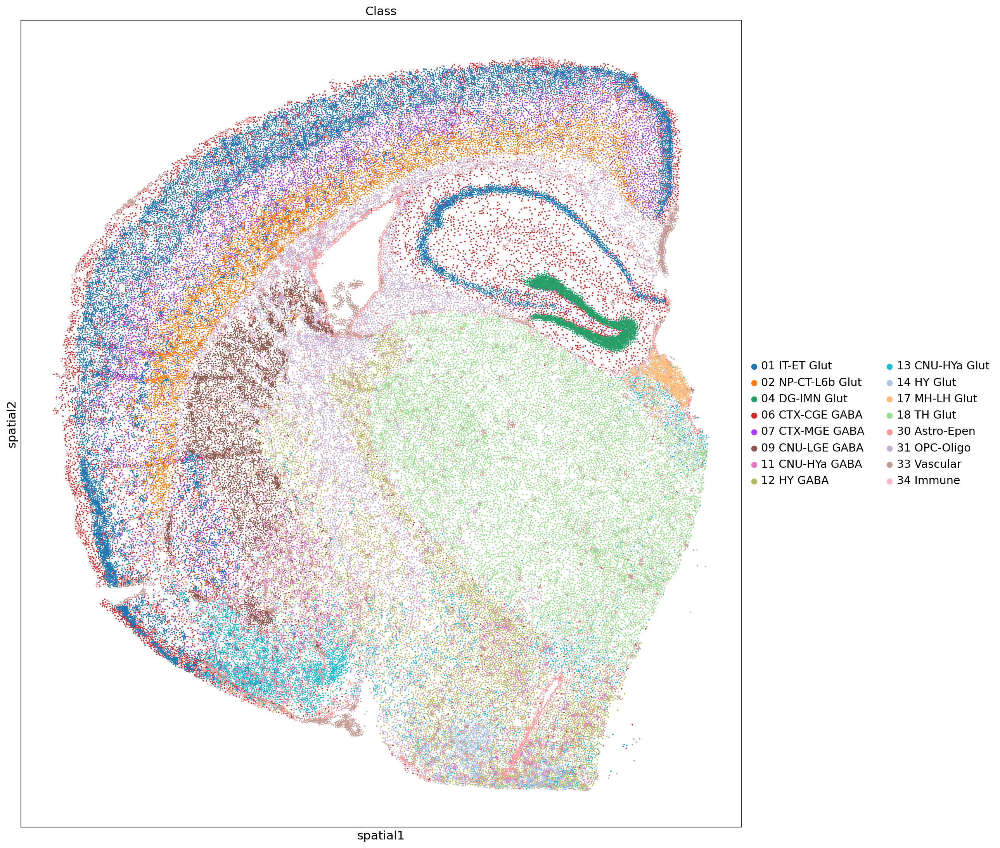

In [36]:
sq.pl.spatial_scatter(
    Sample_4,
    library_id="spatial",
    shape=None,
    color=[
        "Class",
    ],
    wspace=0.4,
)

In [47]:
# List of AnnData objects (e.g., adata1, adata2, ...)
adatas = [Sample_895, Sample_894, Sample_898,Sample_896,Sample_897,Sample_18,Sample_886,Sample_890,Sample_891,Sample_4,Sample_5,Sample_3,Sample_706,Sample_707,Sample_709T]  # Replace with your actual AnnData objects

# Initialize an empty list to store the counts per region for each sample in each AnnData object
region_counts = []

# Loop through each AnnData object to count occurrences of regions
for adata in adatas:
    # Count the occurrences of each region in the "Regions" column
    counts_per_region = adata.obs["Class"].value_counts()
    
    # Append the result (this will be a pandas Series for each adata)
    region_counts.append(counts_per_region)

# Convert the list of Series into a DataFrame
counts_df = pd.DataFrame(region_counts).transpose()

# Label columns (each corresponds to an AnnData object)
counts_df.columns = [f"adata{i+1}" for i in range(len(adatas))]
counts_df.columns = [adata.obs["Sample"].iloc[0] for adata in adatas]



In [50]:
counts_df.fillna(0)

,895,894,898,896,897,18,886,890,891,4,5,3,706,707,709T
Class,,,,,,,,,,,,,,,
IT-ET Glut,11920,16691,11323,14250,10092,11601,10720,11586,10951,12673,11648,11164,13636,9610,11156
TH Glut,9167,12429,19137,10675,7509,9667,220,9107,7960,10283,8033,7478,10326,6780,8908
CTX-CGE GABA,8062,7297,7165,8406,6340,7088,6897,8296,8494,6390,9649,7224,9258,7419,6532
OPC-Oligo,8027,8769,13121,7663,5428,7012,3326,4901,4369,6800,5490,7129,12310,7008,7548
CTX-MGE GABA,6815,7818,5760,7212,5358,6584,5018,5922,6436,5222,5721,7271,7586,5592,6592
NP-CT-L6b Glut,4851,6510,5652,5311,4129,4464,5799,5047,3866,5202,3453,4370,6562,3932,4693
HY GABA,4845,7702,4727,5523,4734,6226,10965,5997,5617,6607,4062,5419,6949,4488,7224
Astro-Epen,3538,5002,8006,4106,2805,3090,4307,4755,4288,5527,5496,3062,6065,2508,3990
CNU-LGE GABA,3515,4735,2946,3313,3067,3115,35,2790,2404,4265,774,2751,4303,2432,4246


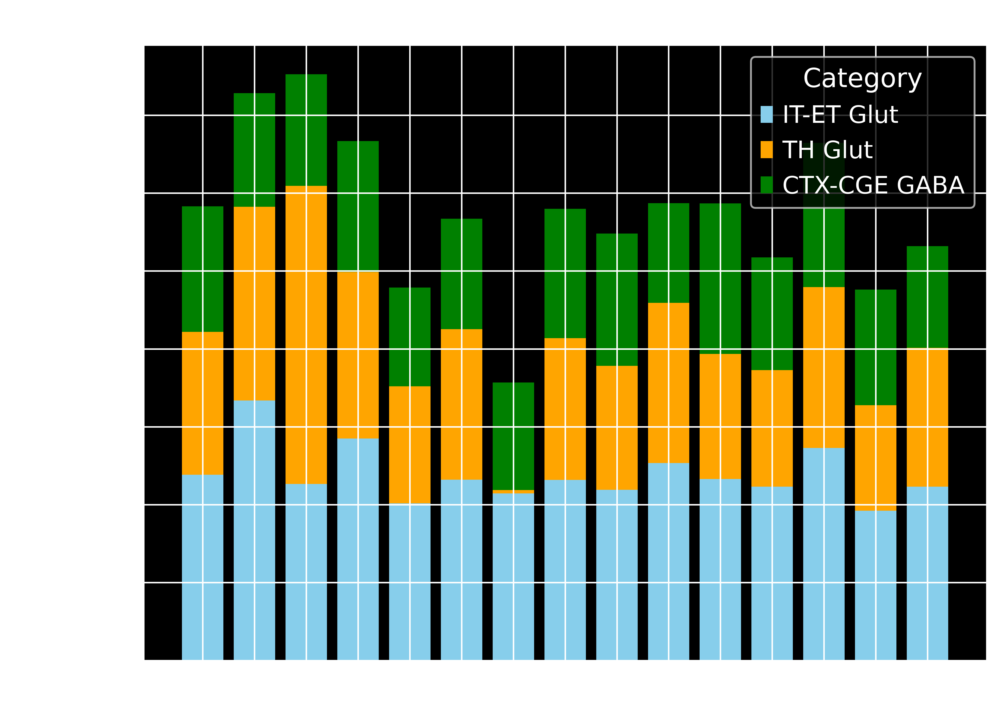

In [49]:
df=counts_df

# Plot stacked barplot
fig, ax = plt.subplots(figsize=(8, 6))

# Cumulative bottom for stacking
bottom = None

# Define colors for each category
colors = ['skyblue', 'orange', 'green']

# Loop through each row (category)
for (category, row_values), color in zip(df.iterrows(), colors):
    ax.bar(df.columns, row_values, label=category, bottom=bottom, color=color)
    bottom = row_values if bottom is None else bottom + row_values

# Customizations
ax.set_ylabel("Counts")
ax.set_title("Stacked Barplot of Count Table")
ax.legend(title="Category")
plt.show()

In [51]:
percentage_df = counts_df.div(counts_df.fillna(0).sum(axis=0), axis=1) * 100

<Axes: >

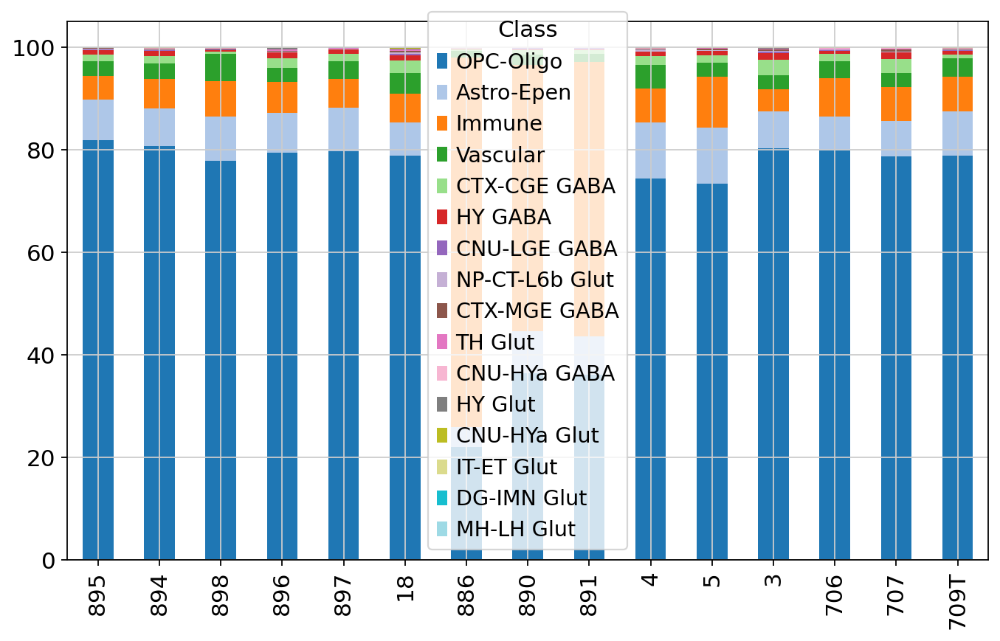

In [42]:
percentage_df.T.plot(kind="bar", stacked=True, figsize=(10, 6), cmap="tab20")

In [52]:
percentage_df 

,895,894,898,896,897,18,886,890,891,4,5,3,706,707,709T
Class,,,,,,,,,,,,,,,
IT-ET Glut,16.307545,17.188964,10.438157,17.064438,16.600595,15.078179,14.662636,14.393619,14.250023,15.996415,16.861610,15.743679,13.680050,15.549659,14.850114
TH Glut,12.541213,12.799811,17.641528,12.783359,12.351751,12.564499,0.300912,11.313887,10.357975,12.979653,11.628547,10.545614,10.359357,10.970519,11.857729
CTX-CGE GABA,11.029482,7.514701,6.605087,10.066222,10.428832,9.212493,9.433601,10.306358,11.052844,8.065738,13.967863,10.187418,9.287907,12.004466,8.694958
OPC-Oligo,10.981599,9.030617,12.095652,9.176476,8.928660,9.113713,4.549247,6.088653,5.685175,8.583258,7.947307,10.053447,12.349766,11.339439,10.047388
CTX-MGE GABA,9.323483,8.051245,5.309881,8.636402,8.813515,8.557429,6.863536,7.357070,8.374865,6.591437,8.281702,10.253698,7.610506,9.048251,8.774826
NP-CT-L6b Glut,6.636569,6.704221,5.210321,6.359946,6.791900,5.801999,7.931775,6.270033,5.030645,6.566192,4.998552,6.162655,6.583198,6.362254,6.247005
HY GABA,6.628360,7.931784,4.357606,6.613817,7.787081,8.092125,14.997743,7.450245,7.309139,8.339645,5.880139,7.641974,6.971448,7.261901,9.616101
Astro-Epen,4.840276,5.151231,7.380366,4.916953,4.614018,4.016169,5.891042,5.907273,5.579773,6.976421,7.955993,4.318089,6.084592,4.058121,5.311219
CNU-LGE GABA,4.808810,4.876265,2.715783,3.967332,5.044989,4.048662,0.047872,3.466097,3.128212,5.383470,1.120440,3.879511,4.316900,3.935148,5.651989


In [59]:
# List of AnnData objects (e.g., adata1, adata2, ...)
adatas = [Sample_895, Sample_894, Sample_898,Sample_896,Sample_897,Sample_18,Sample_886,Sample_890,Sample_891,Sample_4,Sample_5,Sample_3,Sample_706,Sample_707,Sample_709T]  # Replace with your actual AnnData objects

region_labels = Sample_895.obs["Region"].unique()
# Initialize an empty list to store the counts per region for each sample in each AnnData object
region_counts = []

# Loop through each AnnData object to count occurrences of regions
for adata in adatas:
    for region_label in region_labels:
    # Count the occurrences of each region in the "Regions" column
        adata = adata[adata.obs["Region"].isin([region_label]), :]
        counts_per_region = adata.obs["Class"].value_counts()
    
    # Append the result (this will be a pandas Series for each adata)
        region_counts.append(counts_per_region)

# Convert the list of Series into a DataFrame
        counts_df = pd.DataFrame(region_counts).transpose()

# Label columns (each corresponds to an AnnData object)
        counts_df.columns = [f"adata{i+1}" for i in range(len(adatas))]
        counts_df.columns = [adata.obs["Sample"].iloc[0] for adata in adatas]


ValueError: Length mismatch: Expected axis has 1 elements, new values have 15 elements

In [75]:
# List of AnnData objects (e.g., adata1, adata2, ...)
adatas = [Sample_895, Sample_894, Sample_898,Sample_896,Sample_897,Sample_18,Sample_886,Sample_890,Sample_891,Sample_4,Sample_5,Sample_3,Sample_706,Sample_707,Sample_709T]  # Replace with your actual AnnData objects

region_labels = Sample_895.obs["Region"].unique()
# Initialize an empty list to store the counts per region for each sample in each AnnData object


# Initialize dictionaries to store count and percentage DataFrames by region
region_counts_dfs = {}
region_percentages_dfs = {}

# Iterate over each region label
for region_label in region_labels:
    # Filter columns corresponding to the current region
    region_columns = [col for col in region_counts_df.columns if f"_{region_label}" in col]
    
    # Create a DataFrame for the current region
    region_df = region_counts_df[region_columns]
    
    # Rename columns to sample names
    region_df.columns = [col.split('_')[0] for col in region_columns]
    
    # Store the count DataFrame
    region_counts_dfs[region_label] = region_df
    
    # Calculate percentages by dividing each value by the column total and multiplying by 100
    region_percentages_df = region_df.div(region_df.sum(axis=0), axis=1) * 100
    
    # Store the percentage DataFrame
    region_percentages_dfs[region_label] = region_percentages_df

In [76]:
region_dfs["Cortex L5"]

,895,894,898,896,897,18,886,890,891,4,5,3,706,707,709T
Class,,,,,,,,,,,,,,,
Astro-Epen,43,57,55,19,24,16,67,26,14,52,32,16,50,12,24
CNU-HYa GABA,5,9,20,3,2,12,35,3,1,6,3,2,6,4,3
CNU-HYa Glut,2,9,7,4,5,4,13,2,0,6,1,1,1,2,5
CNU-LGE GABA,2,14,11,3,4,4,1,2,2,7,4,2,7,0,0
CTX-CGE GABA,363,359,331,372,340,272,825,440,408,400,407,301,315,237,311
CTX-MGE GABA,2433,2896,2019,2426,1958,2370,1844,2254,2175,2073,2145,2550,2733,1929,2237
DG-IMN Glut,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0
HY GABA,1,2,2,2,0,2,9,2,2,2,4,2,2,1,2
HY Glut,0,0,0,0,0,0,8,0,0,0,0,0,0,0,1


In [77]:
region_dfs["Hypothalamus"]

,895,894,898,896,897,18,886,890,891,4,5,3,706,707,709T
Class,,,,,,,,,,,,,,,
Astro-Epen,411,1057,2276,709,509,528,1633,967,792,1344,533,523,931,293,772
CNU-HYa GABA,689,2549,4107,1334,727,1471,520,563,1298,1507,403,651,2007,485,957
CNU-HYa Glut,544,1427,1711,1077,676,2080,1319,418,927,1189,1786,2702,2580,1601,1142
CNU-LGE GABA,23,130,66,65,51,57,17,15,16,77,17,36,40,26,44
CTX-CGE GABA,52,92,64,129,55,135,451,95,96,85,77,220,112,129,77
CTX-MGE GABA,17,28,30,31,13,54,215,18,24,31,32,68,51,70,27
DG-IMN Glut,0,2,19,0,1,2,27,0,0,1,0,0,3,0,1
HY GABA,3425,5798,3616,4013,3308,4842,10504,4299,4180,4983,3523,3961,5106,3270,5157
HY Glut,1613,3226,6215,2700,792,3107,2872,1484,3185,1706,1555,2563,4048,1278,1411


In [78]:
region_percentages_dfs["Hypothalamus"]

,895,894,898,896,897,18,886,890,891,4,5,3,706,707,709T
Class,,,,,,,,,,,,,,,
Astro-Epen,5.477079,6.507819,10.390796,6.366739,7.194346,3.888930,5.271143,8.104937,5.799649,10.759747,6.076844,4.317675,5.536723,3.558416,7.029045
CNU-HYa GABA,9.181770,15.693880,18.750000,11.979167,10.275618,10.834500,1.678502,4.718800,9.504979,12.064687,4.594687,5.374391,11.935772,5.890211,8.713466
CNU-HYa Glut,7.249467,8.785864,7.811359,9.671336,9.554770,15.320027,4.257586,3.503478,6.788225,9.518854,20.362558,22.306613,15.343443,19.443770,10.397888
CNU-LGE GABA,0.306503,0.800394,0.301315,0.583693,0.720848,0.419828,0.054874,0.125723,0.117165,0.616444,0.193821,0.297201,0.237883,0.315764,0.400619
CTX-CGE GABA,0.692964,0.566433,0.292184,1.158405,0.777385,0.994329,1.455778,0.796245,0.702988,0.680490,0.877893,1.816230,0.666072,1.566675,0.701083
CTX-MGE GABA,0.226546,0.172393,0.136961,0.278376,0.183746,0.397731,0.693996,0.150867,0.175747,0.248179,0.364839,0.561380,0.303301,0.850134,0.245834
DG-IMN Glut,0.000000,0.012314,0.086742,0.000000,0.014134,0.014731,0.087153,0.000000,0.000000,0.008006,0.000000,0.000000,0.017841,0.000000,0.009105
HY GABA,45.642324,35.697574,16.508400,36.036279,46.756184,35.663254,33.905746,36.032185,30.609256,39.892723,40.166458,32.700405,30.365745,39.713384,46.954384
HY Glut,21.495203,19.862086,28.373813,24.245690,11.194346,22.884290,9.270497,12.438186,23.323081,13.657834,17.728879,21.159085,24.073744,15.521010,12.847127


In [79]:
region_dfs["Fiber tracts"]

,895,894,898,896,897,18,886,890,891,4,5,3,706,707,709T
Class,,,,,,,,,,,,,,,
Astro-Epen,554,462,830,506,363,387,119,604,543,591,551,440,704,434,518
CNU-HYa GABA,3,6,7,0,3,8,2,3,3,7,2,1,9,12,6
CNU-HYa Glut,2,3,0,7,2,9,0,1,1,2,2,10,12,3,4
CNU-LGE GABA,13,7,12,7,1,14,0,20,14,5,3,18,11,6,5
CTX-CGE GABA,92,92,46,123,64,143,10,57,44,90,74,180,140,174,49
CTX-MGE GABA,5,13,5,15,3,18,2,0,5,9,15,16,10,19,8
DG-IMN Glut,0,1,2,1,0,1,0,0,0,1,1,1,1,0,0
HY GABA,59,63,20,70,34,59,6,11,20,47,37,81,72,80,44
HY Glut,3,2,4,12,3,6,1,0,1,1,2,2,3,1,4


In [89]:
region_dfs["Thalamus 2"]

,895,894,898,896,897,18,886,890,891,4,5,3,706,707,709T
Class,,,,,,,,,,,,,,,
Astro-Epen,103,317,622,234,149,248,1,205,180,204,148,60,190,59,130
CNU-HYa GABA,2,2,11,3,1,5,0,0,0,0,0,1,2,0,2
CNU-HYa Glut,79,262,205,268,104,187,0,90,117,190,118,311,210,174,118
CNU-LGE GABA,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0
CTX-CGE GABA,5,8,15,9,4,5,0,4,3,8,6,11,4,9,2
CTX-MGE GABA,1,0,0,0,0,0,0,0,0,0,0,0,0,1,4
DG-IMN Glut,0,0,16,1,1,3,0,0,0,0,0,0,1,0,0
HY GABA,16,25,19,16,8,16,0,10,26,21,15,58,23,40,12
HY Glut,126,428,1270,488,98,588,1,279,598,234,225,317,475,164,190


In [90]:
region_percentages_dfs["Thalamus 2"]

,895,894,898,896,897,18,886,890,891,4,5,3,706,707,709T
Class,,,,,,,,,,,,,,,
Astro-Epen,3.714389,5.273665,5.233047,4.927353,5.704441,5.192630,25.0,5.507792,4.447739,4.483516,4.444444,2.016129,4.005903,2.198212,3.361779
CNU-HYa GABA,0.072124,0.033272,0.092546,0.063171,0.038285,0.104690,0.0,0.000000,0.000000,0.000000,0.000000,0.033602,0.042167,0.000000,0.051720
CNU-HYa Glut,2.848900,4.358676,1.724718,5.643293,3.981623,3.915410,0.0,2.418055,2.891030,4.175824,3.543544,10.450269,4.427577,6.482861,3.051461
CNU-LGE GABA,0.000000,0.016636,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
CTX-CGE GABA,0.180310,0.133089,0.126199,0.189514,0.153139,0.104690,0.0,0.107469,0.074129,0.175824,0.180180,0.369624,0.084335,0.335320,0.051720
CTX-MGE GABA,0.036062,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.037258,0.103439
DG-IMN Glut,0.000000,0.000000,0.134612,0.021057,0.038285,0.062814,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.021084,0.000000,0.000000
HY GABA,0.576992,0.415904,0.159852,0.336913,0.306279,0.335008,0.0,0.268673,0.642451,0.461538,0.450450,1.948925,0.484925,1.490313,0.310318
HY Glut,4.543815,7.120279,10.684839,10.275848,3.751914,12.311558,25.0,7.495970,14.776378,5.142857,6.756757,10.651882,10.014759,6.110283,4.913370


In [91]:
region_dfs["Cortex L6b"]

,895,894,898,896,897,18,886,890,891,4,5,3,706,707,709T
Class,,,,,,,,,,,,,,,
Astro-Epen,51,78,83,45,60,25,277,80,64,84,52,24,51,23,62
CNU-HYa GABA,4,5,6,4,7,5,19,3,2,7,5,2,7,2,3
CNU-HYa Glut,4,14,7,6,5,1,4,8,2,29,3,2,4,0,4
CNU-LGE GABA,6,5,5,3,4,6,2,4,1,10,1,5,4,1,5
CTX-CGE GABA,136,166,130,154,148,130,527,170,141,132,157,136,153,109,151
CTX-MGE GABA,223,315,187,198,205,219,338,274,195,210,179,279,287,176,294
DG-IMN Glut,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0
HY GABA,0,2,2,5,0,1,10,3,1,1,1,1,1,2,2
HY Glut,0,0,0,0,0,0,10,1,0,3,0,0,0,0,0


In [92]:
region_percentages_dfs["Cortex L6b"]

,895,894,898,896,897,18,886,890,891,4,5,3,706,707,709T
Class,,,,,,,,,,,,,,,
Astro-Epen,2.907640,3.392779,4.269547,2.501390,3.795066,1.579280,6.021739,4.121587,4.463040,4.048193,3.909774,1.563518,2.160102,1.722846,3.232534
CNU-HYa GABA,0.228050,0.217486,0.308642,0.222346,0.442758,0.315856,0.413043,0.154560,0.139470,0.337349,0.375940,0.130293,0.296485,0.149813,0.156413
CNU-HYa Glut,0.228050,0.608960,0.360082,0.333519,0.316256,0.063171,0.086957,0.412159,0.139470,1.397590,0.225564,0.130293,0.169420,0.000000,0.208551
CNU-LGE GABA,0.342075,0.217486,0.257202,0.166759,0.253004,0.379027,0.043478,0.206079,0.069735,0.481928,0.075188,0.325733,0.169420,0.074906,0.260688
CTX-CGE GABA,7.753706,7.220531,6.687243,8.560311,9.361164,8.212255,11.456522,8.758372,9.832636,6.361446,11.804511,8.859935,6.480305,8.164794,7.872784
CTX-MGE GABA,12.713797,13.701609,9.619342,11.006115,12.966477,13.834491,7.347826,14.116435,13.598326,10.120482,13.458647,18.175896,12.155866,13.183521,15.328467
DG-IMN Glut,0.000000,0.000000,0.051440,0.000000,0.000000,0.000000,0.021739,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
HY GABA,0.000000,0.086994,0.102881,0.277932,0.000000,0.063171,0.217391,0.154560,0.069735,0.048193,0.075188,0.065147,0.042355,0.149813,0.104275
HY Glut,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.217391,0.051520,0.000000,0.144578,0.000000,0.000000,0.000000,0.000000,0.000000
